Import Library & Preprocessing Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="darkgrid")

df = pd.read_csv('AEP_hourly.csv')

df['Datetime'] = pd.to_datetime(df['Datetime'])

df = df.set_index('Datetime')
df = df.sort_index()

df = df.iloc[-5000:]

print(f"Data ok")
print(f"Total baris: {len(df)}")
print(f"Rentang waktu: {df.index.min()} sampai {df.index.max()}")
print("\n5 Data teratas:")
print(df.head())

Data ok
Total baris: 5000
Rentang waktu: 2018-01-06 16:00:00 sampai 2018-08-03 00:00:00

5 Data teratas:
                      AEP_MW
Datetime                    
2018-01-06 16:00:00  19328.0
2018-01-06 17:00:00  19618.0
2018-01-06 18:00:00  20639.0
2018-01-06 19:00:00  21388.0
2018-01-06 20:00:00  21510.0


Exploratory Data Analysis (EDA)

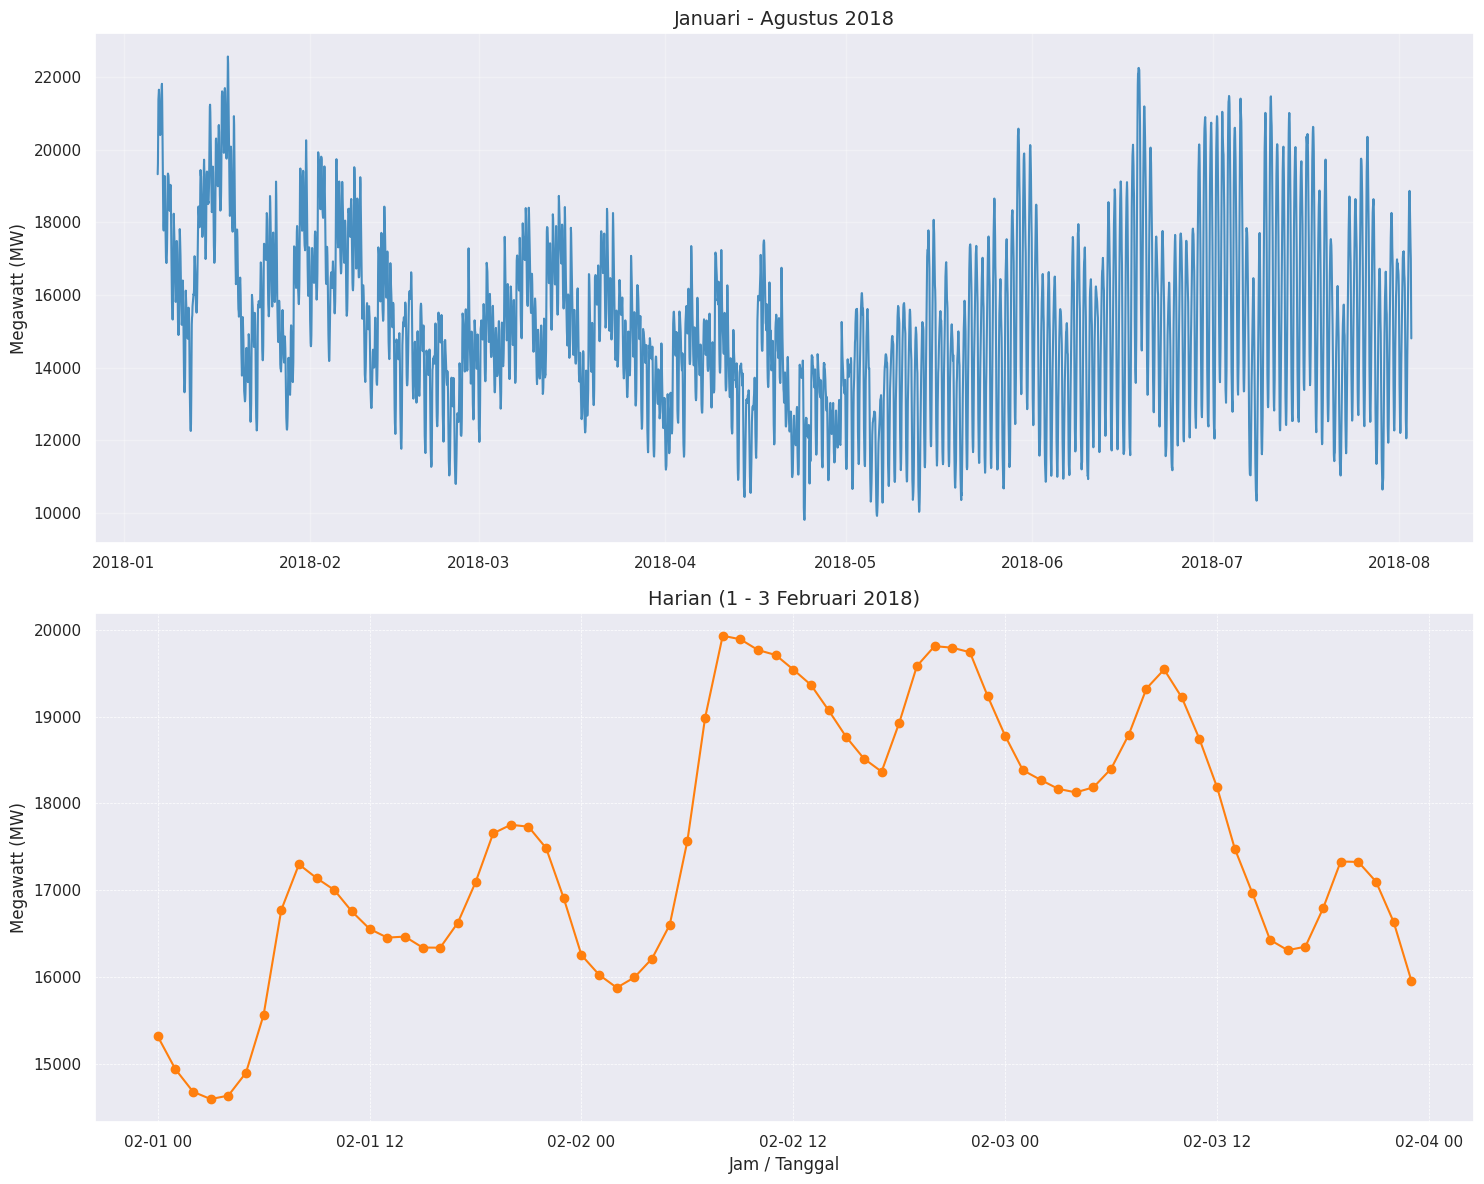


Statistik Deskriptif Data:
             AEP_MW
count   5000.000000
mean   15146.440600
std     2394.045858
min     9815.000000
25%    13413.750000
50%    14954.000000
75%    16701.000000
max    22567.000000


In [ ]:
plt.figure(figsize=(15, 12))

plt.subplot(2, 1, 1)
plt.plot(df.index, df['AEP_MW'], color='tab:blue', alpha=0.8)
plt.title('Januari - Agustus 2018', fontsize=14)
plt.ylabel('Megawatt (MW)')
plt.grid(True, alpha=0.3)

subset_zoom = df.loc['2018-02-01':'2018-02-03']

plt.subplot(2, 1, 2)
plt.plot(subset_zoom.index, subset_zoom['AEP_MW'], color='tab:orange', marker='o', linestyle='-')
plt.title('Harian (1 - 3 Februari 2018)', fontsize=14)
plt.ylabel('Megawatt (MW)')
plt.xlabel('Jam / Tanggal')

plt.grid(True, which='both', linestyle='--', linewidth=0.5)

plt.tight_layout()
plt.show()

print("\nStatistik Deskriptif Data:")
print(df.describe())

Modeling buat isolation forest

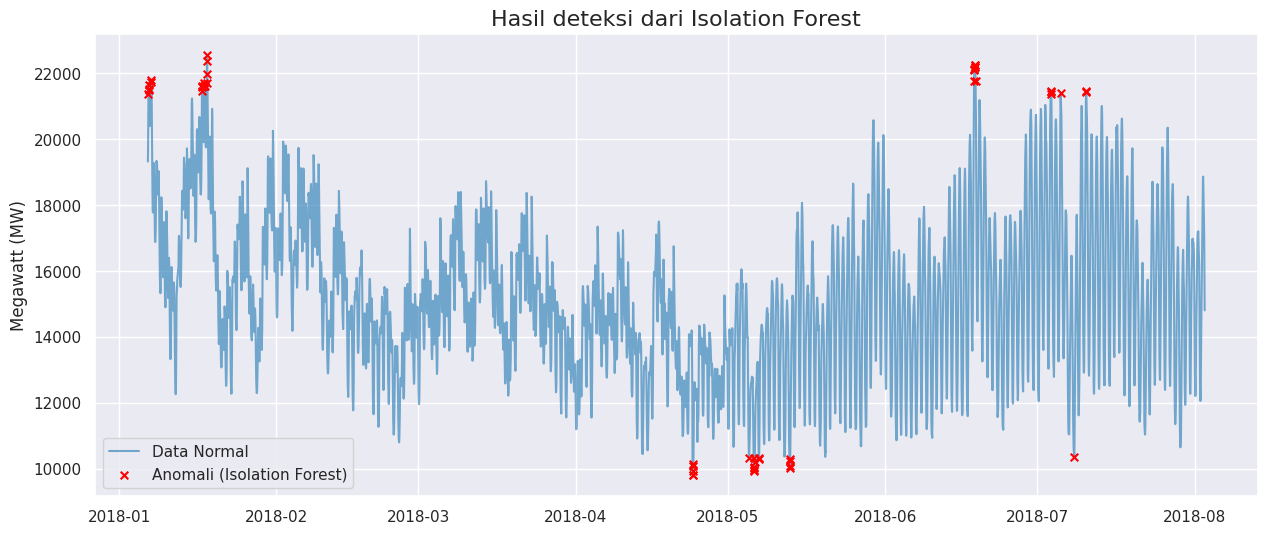

Total Data: 5000
Jumlah Anomali : 49 (0.98%)


In [ ]:
from sklearn.ensemble import IsolationForest
#untuk klasifikasi, regresi, clustering
# mulai training model buat isolation forest

# siapin data
data_model = df[['AEP_MW']]

# buat model
model_iso = IsolationForest(contamination=0.01, random_state=42)

model_iso.fit(data_model)

# Prediksi jadi kalau 1 = normal lalu -1 = Anomali
df['anomaly_iso'] = model_iso.predict(data_model)

# ngambil data yang label anomali
anomalies_iso = df[df['anomaly_iso'] == -1]

# untuk grafik
plt.figure(figsize=(15, 6))

# garis biru untuk yang normal
plt.plot(df.index, df['AEP_MW'], color='tab:blue', alpha=0.6, label='Data Normal')

# titik merah untuk anomali
plt.scatter(anomalies_iso.index, anomalies_iso['AEP_MW'], color='red', label='Anomali (Isolation Forest)', s=30, marker='x', zorder=10)

plt.title('Hasil deteksi dari Isolation Forest', fontsize=16)
plt.ylabel('Megawatt (MW)')
plt.legend()
plt.show()

print(f"Total Data: {len(df)}")
print(f"Jumlah Anomali : {len(anomalies_iso)} ({len(anomalies_iso)/len(df)*100:.2f}%)")

Modeling buat LSTM

Input LSTM: (4970, 30, 1)
(Jumlah Data, Panjang Window, Jumlah Fitur)

Training
Epoch 1/15


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


140/140 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - loss: 0.0483 - val_loss: 0.0253
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - loss: 0.0129 - val_loss: 0.0028
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0057 - val_loss: 0.0016
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0048 - val_loss: 0.0014
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.0039 - val_loss: 0.0019
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0032 - val_loss: 9.0786e-04
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 0.0026 - val_loss: 0.0016
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0028 - val_loss: 0.0010
Epoch 9/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0023 - val_loss: 7.8919e-04
Epoch 10/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - loss: 0.0022 - val_loss: 8.2226e-04
Epoch 11/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0021 - val_loss: 0.0011
Epoch 12/15
140/140 ━━━━━━━━━━━━━━━━━━━━

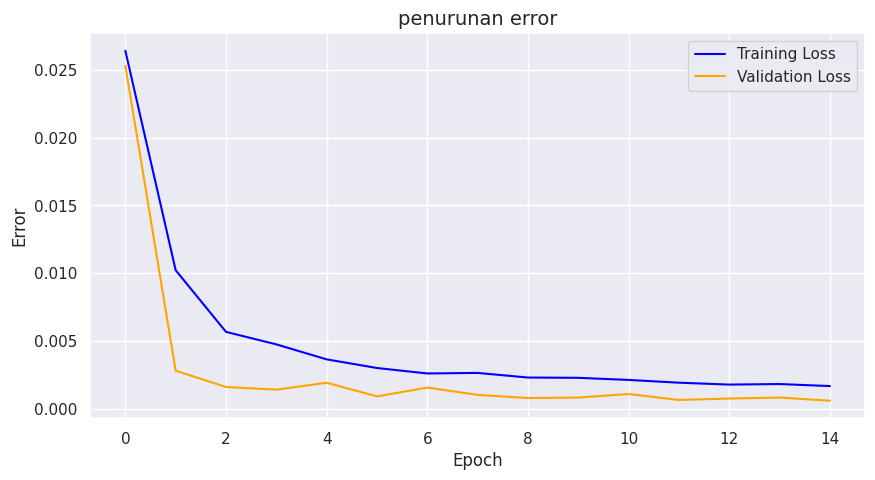

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout

# preprocesing buat LSTM

# mengubah rentang data jadi 0 s.d 1 dari yang awalnya angka besar
scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(df[['AEP_MW']])

# buat Sequence waktu untuk melihat 30 jam ke belakang (X) dan menebak 1 jam ke depan (y)
TIME_STEPS = 30

def create_sequences(data, time_steps):
    X, y = [], []
    for i in range(len(data) - time_steps):
        X.append(data[i:(i + time_steps)])
        y.append(data[i + time_steps])
    return np.array(X), np.array(y)

X_lstm, y_lstm = create_sequences(data_scaled, TIME_STEPS)

print(f"Input LSTM: {X_lstm.shape}")
print("(Jumlah Data, Panjang Window, Jumlah Fitur)")

# Arsitektur modelnya
model = Sequential()

# LSTM mengset neuron 50
model.add(LSTM(units=50, return_sequences=False, input_shape=(X_lstm.shape[1], 1)))

# Dropout buat mematikan 20% neuron secara acak saat belajar
model.add(Dropout(0.2))

# Output megawat 1 jam kedepan dari 30 jam
model.add(Dense(units=1))

# compile untuk cara belajar, adam = adaptif moment estimation
model.compile(optimizer='adam', loss='mean_squared_error')

# bagian training
print("\nTraining")
history = model.fit(X_lstm, y_lstm, epochs=15, batch_size=32, validation_split=0.1, verbose=1)

# untuk cek grafik
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
plt.title('penurunan error', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Error')
plt.legend()
plt.show()

Evaluasi Model, contoh studi kasus (melihat data lebih dekat) & tampilkan metrik

156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Threshold : 1006.75 MW


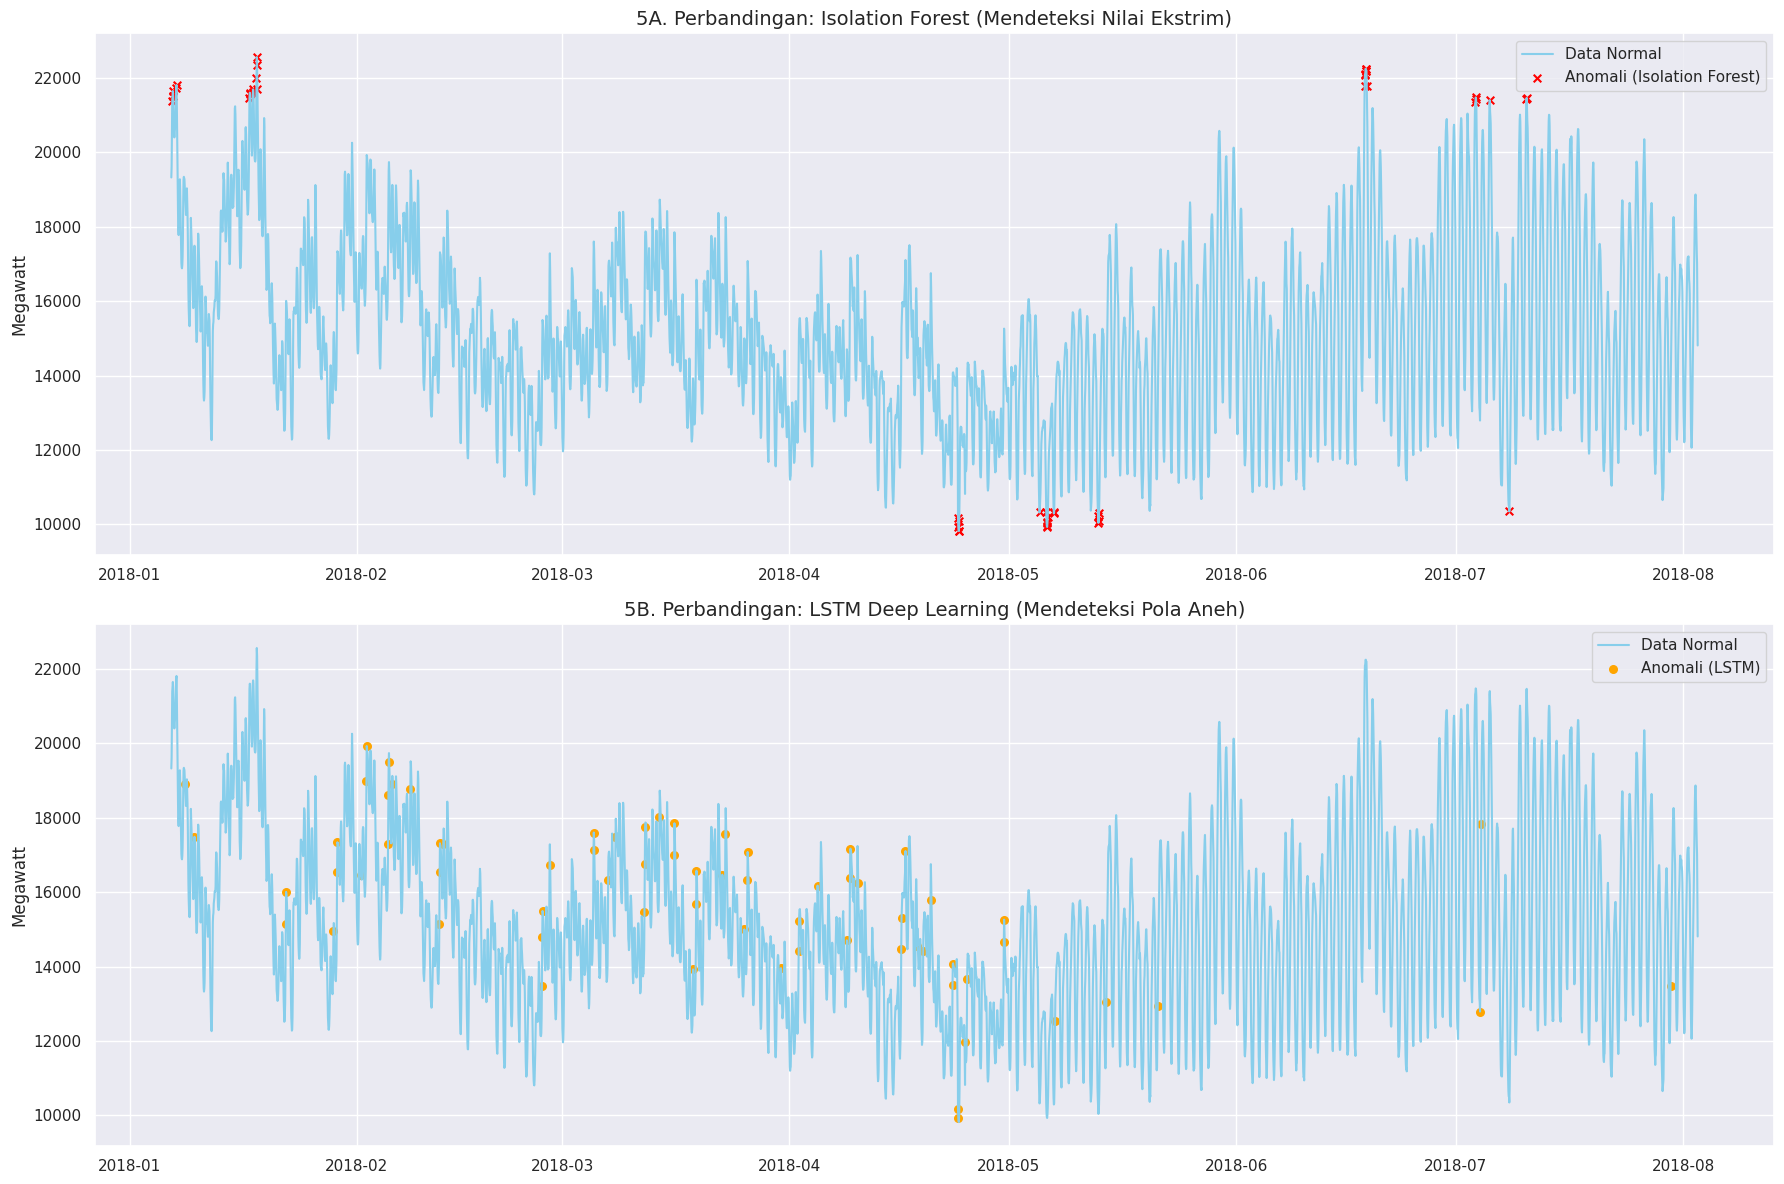

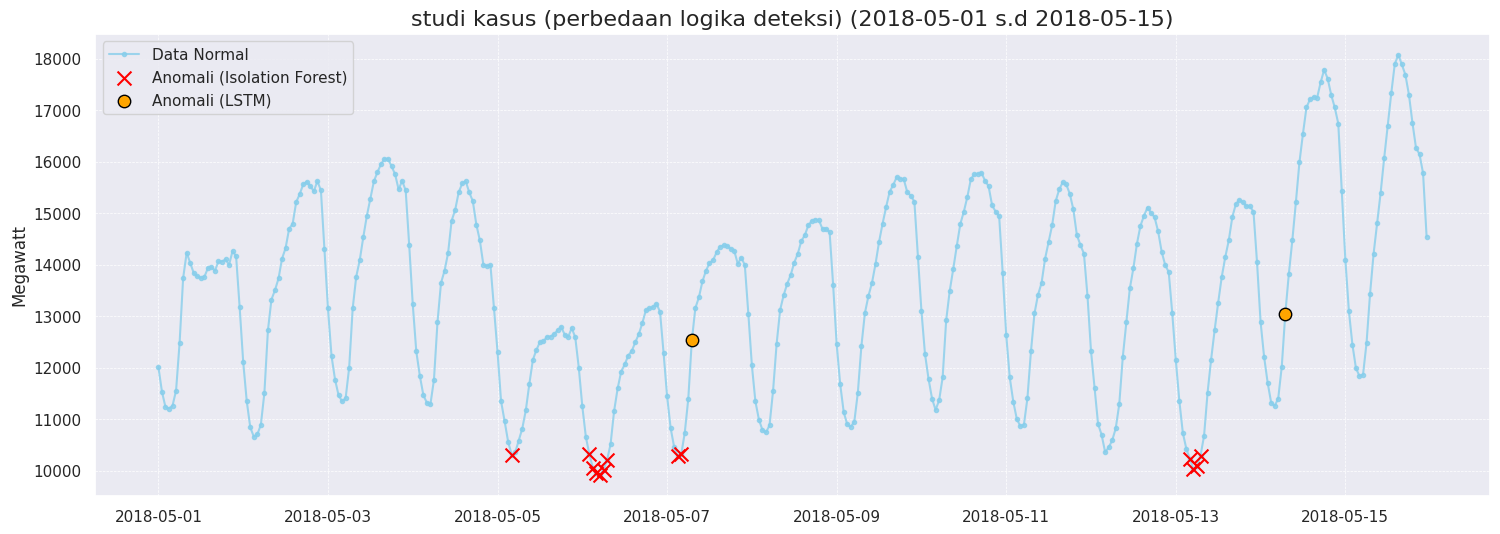

Akurasi model LSTM:
MAE (rata-rata meleset): 285.23 MW
RMSE (tingkat error): 373.09 MW
Perbandingan deteksi:
Total anomali isolation forest : 49
Total anomali LSTM             : 69
Anomali irisan: 2 kejadian


In [ ]:
# mendeteksi anomali

# untuk prediksi
predicted = model.predict(X_lstm)

predicted_inv = scaler.inverse_transform(predicted)
y_true_inv = scaler.inverse_transform(y_lstm.reshape(-1, 1))

# hitung MAE
loss_mae = np.abs(predicted_inv - y_true_inv)

# buat tresshold (toleransi) rumusnya rata-rata error + (3 * standar deviasi)
threshold = np.mean(loss_mae) + 3 * np.std(loss_mae)
print(f"Threshold : {threshold:.2f} MW")

# filter data anomali
anomaly_indices = np.where(loss_mae > threshold)[0] + TIME_STEPS
lstm_anomalies = df.iloc[anomaly_indices]

# grafik perbandingan
plt.figure(figsize=(18, 12))

# grafik isolation forest
plt.subplot(2, 1, 1)
plt.plot(df.index, df['AEP_MW'], color='skyblue', label='Data Normal')
plt.scatter(anomalies_iso.index, anomalies_iso['AEP_MW'], color='red', label='Anomali (Isolation Forest)', s=30, marker='x')
plt.title('5A. Perbandingan: Isolation Forest (Mendeteksi Nilai Ekstrim)', fontsize=14)
plt.ylabel('Megawatt')
plt.legend()

# grafik LSTM
plt.subplot(2, 1, 2)
plt.plot(df.index, df['AEP_MW'], color='skyblue', label='Data Normal')
plt.scatter(lstm_anomalies.index, lstm_anomalies['AEP_MW'], color='orange', label='Anomali (LSTM)', s=30, marker='o')
plt.title(f'5B. Perbandingan: LSTM Deep Learning (Mendeteksi Pola Aneh)', fontsize=14)
plt.ylabel('Megawatt')
plt.legend()

plt.tight_layout()
plt.show()

# contoh studi kasus mei 2018
start_date = '2018-05-01'
end_date = '2018-05-15'

subset_df = df.loc[start_date:end_date]
subset_iso = anomalies_iso.loc[start_date:end_date]
subset_lstm = lstm_anomalies.loc[start_date:end_date]

plt.figure(figsize=(18, 6))
plt.plot(subset_df.index, subset_df['AEP_MW'], color='skyblue', marker='.', linestyle='-', alpha=0.8, label='Data Normal')
# merah buat anomali isolation forest
plt.scatter(subset_iso.index, subset_iso['AEP_MW'], color='red', s=100, marker='x', label='Anomali (Isolation Forest)', zorder=10)

# orange buat anomali LSTM
plt.scatter(subset_lstm.index, subset_lstm['AEP_MW'], color='orange', s=80, marker='o', edgecolors='black', label='Anomali (LSTM)', zorder=10)

plt.title(f'studi kasus (perbedaan logika deteksi) ({start_date} s.d {end_date})', fontsize=16)
plt.ylabel('Megawatt')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.legend()
plt.show()


# metric evaluasi
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_true_inv, predicted_inv)
rmse = np.sqrt(mean_squared_error(y_true_inv, predicted_inv))

# buat hitung irisan
set_iso = set(anomalies_iso.index)
set_lstm = set(lstm_anomalies.index)
irisan = set_iso.intersection(set_lstm)

print(f"Akurasi model LSTM:")
print(f"MAE (rata-rata meleset): {mae:.2f} MW")
print(f"RMSE (tingkat error): {rmse:.2f} MW")
print(f"Perbandingan deteksi:")
print(f"Total anomali isolation forest : {len(set_iso)}")
print(f"Total anomali LSTM             : {len(set_lstm)}")
print(f"Anomali irisan: {len(irisan)} kejadian")

Diagram Venn

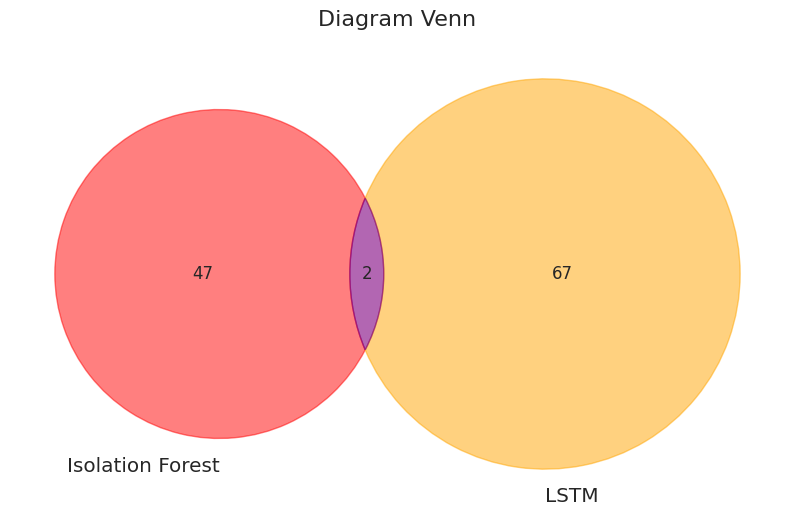

Isolation forest: 47 kejadian
LSTM: 67 kejadian
Irisan: 2 kejadian


In [ ]:
# diagram venn

!pip install matplotlib-venn > /dev/null

from matplotlib_venn import venn2
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

set_iso = set(anomalies_iso.index)
set_lstm = set(lstm_anomalies.index)

# buat diagram
venn = venn2([set_iso, set_lstm], set_labels=('Isolation Forest', 'LSTM'))

if venn.get_patch_by_id('10'):
    venn.get_patch_by_id('10').set_color('red')
    venn.get_patch_by_id('10').set_alpha(0.5)

if venn.get_patch_by_id('01'):
    venn.get_patch_by_id('01').set_color('orange')
    venn.get_patch_by_id('01').set_alpha(0.5)

if venn.get_patch_by_id('11'):
    venn.get_patch_by_id('11').set_color('purple')
    venn.get_patch_by_id('11').set_alpha(0.6)

plt.title("Diagram Venn", fontsize=16)
plt.show()

print(f"Isolation forest: {len(set_iso - set_lstm)} kejadian")
print(f"LSTM: {len(set_lstm - set_iso)} kejadian")
print(f"Irisan: {len(set_iso.intersection(set_lstm))} kejadian")